# Sensibilidad de fases — Isotropic Ring, inport 3

**Perturbacion tipo B (uniforme):** mismo delta sumado a TODAS las TBUs dinamicas.
La logica de perturbacion corre dentro de `medir_loop_po_est.py` (accion `setear_reto_perturbado_B`).
El notebook solo manda `reto_idx + delta` y no necesita tener los retos en local.

### Cambio en medir_loop_po_est.py
Anadir este bloque junto al resto de acciones:

```python
if accion == 'setear_reto_perturbado_B':
    inport   = cmd['inport']
    reto_idx = cmd['reto_idx']
    delta    = float(cmd['delta'])

    challenges, route_pucs_inport, dynamic_pucs, outports = cargar_retos(inport)
    reto_base = challenges[reto_idx]

    # Perturbacion tipo B: suma delta a todas las TBUs dinamicas (mod 2*pi)
    # La ruta NO se reprograma; debe estar ya programada desde setear_reto
    reto_pert = {
        puc_id: [(reto_base[puc_id][0] + delta) % (2.0 * 3.141592653589793),
                  reto_base[puc_id][1]]
        for puc_id in dynamic_pucs
    }
    sl.set_driven_phases(reto_pert, compensate_passive_phase=False)

    respuesta = {'status': 'ok', 'inport': inport, 'reto_idx': reto_idx,
                 'delta': delta, 'n_pucs': len(reto_pert)}
    print(json.dumps(respuesta))
    sys.stdout.flush()
    continue
```

In [33]:
import json, time
import numpy as np
import matplotlib.pyplot as plt
import paramiko
from pathlib import Path
from datetime import datetime


# Parametros del experimento
INPORT  = 1
OUTPORT_POL = 39
N_RETOS = 20
DELTAS  = [2,2.5,3]  # rad
WAIT_S  = 2.0   # segundos entre reprogramaciones

OUT_DIR = Path(r'C:\Users\User MVP\Desktop\Oxel\sensibilidad_fases')


In [10]:
!pip install matplotlib

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   -------------------------- ------------- 6.3/9.5 MB 33.4 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 24.4 MB/s  0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 25.6 MB/s  0:00:00
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   -------------------------------------- - 7.1/7.3 MB 41.7 MB/s eta 0:00:01
   ---------------------------------------- 7.3/7.3 MB 32.3 MB/s  0:00:00

   ---------------------------------------- 0/7 [pyparsing]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- -----

In [34]:
SL_HOST      = '10.42.0.125'
SL_USER      = 'smartlight'
SL_PASSWORD  = '29c6b8177fdf9b4523e93474d04a0ffa'
SL_KEY_FILE  = None
SL_WORK_DIR  = '/home/smartlight/Oxel/VIGO'

ssh = paramiko.SSHClient()
ssh.set_missing_host_key_policy(paramiko.AutoAddPolicy())

if SL_KEY_FILE:
    ssh.connect(SL_HOST, username=SL_USER, key_filename=SL_KEY_FILE)
else:
    ssh.connect(SL_HOST, username=SL_USER, password=SL_PASSWORD)

print(f'SSH conectado a {SL_HOST}') 


stdin, stdout, stderr = ssh.exec_command(
    f'cd {SL_WORK_DIR} && /home/smartlight/.venvs/ipronics/bin/python medir_loop_po_est.py'
)


SSH conectado a 10.42.0.125


In [11]:
try:
    ssh.close()
except:
    pass

In [35]:
import time
time.sleep(2)  # dar tiempo a que el script arranque o falle
err = stderr.read(4096).decode(errors='replace')
print("STDERR:", err if err else "(vacío)")

KeyboardInterrupt: 

In [28]:
def sl_send(cmd: dict) -> dict:
    stdin.write((json.dumps(cmd) + '\n'))
    stdin.flush()
    resp = stdout.readline()
    return json.loads(resp)

print('sl_send() lista.')
def preparar_externo(inport, outport_prueba):
    """Configura el chip para que el medidor analógico externo pueda leer
    la salida. Después de llamar a esto, ajusta la polarización a mano
    mirando el medidor analógico conectado físicamente al puerto."""
    cmd = {'accion': 'preparar_externo', 'inport': inport, 'outport': outport_prueba}
    stdin.write(json.dumps(cmd) + '\n')
    stdin.flush()
    res = json.loads(stdout.readline())

    if 'error' in res:
        print(f'⚠ Error: {res["error"]}')
        return None

    print(f'✓ {res["status"]}')
    return res


sl_send() lista.


In [36]:
resp = sl_send({'accion': 'preparar_externo', 'inport': INPORT, 'outport': OUTPORT_POL})
print(resp['status'])
print(f'Ajusta la polarizacion en el puerto {OUTPORT_POL} y ejecuta la celda siguiente.')

OSError: Socket is closed

Socket exception: An existing connection was forcibly closed by the remote host (10054)


In [32]:
ps aux | grep medir_loop

SyntaxError: invalid syntax (3891207200.py, line 1)

Socket exception: An existing connection was forcibly closed by the remote host (10054)


Potencias desde inport=1 (top 10):
  puerto 39:   -2.77 dBm <-- OUTPORT_POL
  puerto 11:  -38.32 dBm
  puerto 14:  -38.35 dBm
  puerto  7:  -38.44 dBm
  puerto 15:  -38.81 dBm
  puerto  0:  -38.86 dBm
  puerto 10:  -38.86 dBm
  puerto  3:  -38.89 dBm
  puerto 19:  -38.91 dBm
  puerto  8:  -38.98 dBm


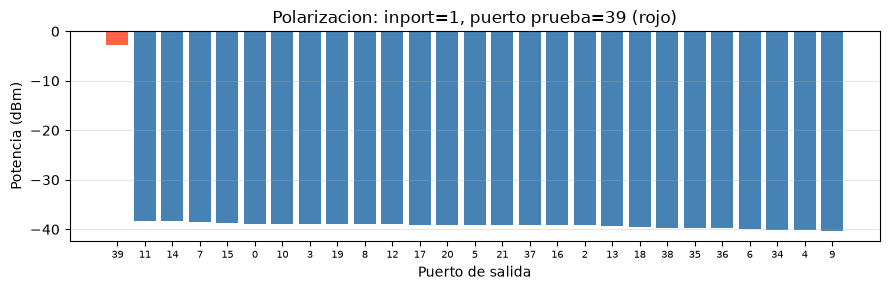

In [16]:
resp_pol   = sl_send({'accion': 'polarizacion', 'inport': INPORT, 'outport': OUTPORT_POL})
powers_pol = {int(k): v for k, v in resp_pol['powers'].items()}
sorted_pts = sorted(powers_pol.items(), key=lambda x: x[1], reverse=True)

print(f'Potencias desde inport={INPORT} (top 10):')
for port, pwr in sorted_pts[:10]:
    marca = ' <-- OUTPORT_POL' if port == OUTPORT_POL else ''
    print(f'  puerto {port:2d}: {pwr:7.2f} dBm{marca}')

all_ports = [p for p, _ in sorted_pts]
all_pwrs  = [v for _, v in sorted_pts]
colors    = ['tomato' if p == OUTPORT_POL else 'steelblue' for p in all_ports]

fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(range(len(all_ports)), all_pwrs, color=colors)
ax.set_xticks(range(len(all_ports)))
ax.set_xticklabels(all_ports, fontsize=7)
ax.set_xlabel('Puerto de salida')
ax.set_ylabel('Potencia (dBm)')
ax.set_title(f'Polarizacion: inport={INPORT}, puerto prueba={OUTPORT_POL} (rojo)')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## Comprobaciones previas
Ejecutar antes del experimento.

In [17]:
def comprobaciones():
    # 1. Baseline del reto 0
    print(f'Programando reto 0 (baseline) en inport={INPORT}...')
    r = sl_send({'accion': 'setear_reto', 'inport': INPORT, 'reto_idx': 0, 'modo': 'anillo'})
    assert r.get('status') == 'ok', f'Error setear_reto: {r}'
    time.sleep(WAIT_S)
    p0 = sl_send({'accion': 'medida_rapida', 'inport': INPORT})
    assert 'powers' in p0, f'Error medida: {p0}'
    print(f'  Baseline: Pmax = {max(p0["powers"].values()):.2f} dBm')

    # 2. Perturbacion grande para confirmar que el chip responde
    print('Aplicando delta = +1.5 rad (setear_reto_perturbado_B)...')
    r2 = sl_send({'accion': 'setear_reto_perturbado_B',
                  'inport': INPORT, 'reto_idx': 0, 'delta': 1.5})
    assert r2.get('status') == 'ok', f'Error setear_reto_perturbado_B: {r2}'
    print(f'  n_pucs dinamicas programadas: {r2["n_pucs"]}')
    time.sleep(WAIT_S)
    p1 = sl_send({'accion': 'medida_rapida', 'inport': INPORT})
    assert 'powers' in p1, f'Error medida: {p1}'

    puertos = sorted(p0['powers'].keys(), key=int)
    diffs   = np.array([p1['powers'][p] - p0['powers'][p] for p in puertos])
    rms_dp  = float(np.sqrt(np.mean(diffs**2)))
    print(f'  RMS cambio potencias (delta=1.5 rad): {rms_dp:.3f} dB')
    if rms_dp < 0.2:
        print('  AVISO: cambio muy pequeno, revisar conexion o retos')
    else:
        print('  [OK] El chip responde a la perturbacion')

    # 3. Restaurar baseline antes de salir
    sl_send({'accion': 'setear_reto', 'inport': INPORT, 'reto_idx': 0, 'modo': 'anillo'})
    time.sleep(WAIT_S)
    print('\n=== Comprobaciones superadas ===')


comprobaciones()


Programando reto 0 (baseline) en inport=1...
  Baseline: Pmax = -19.92 dBm
Aplicando delta = +1.5 rad (setear_reto_perturbado_B)...
  n_pucs dinamicas programadas: 60
  RMS cambio potencias (delta=1.5 rad): 6.800 dB
  [OK] El chip responde a la perturbacion

=== Comprobaciones superadas ===


## Experimento principal

In [ ]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
ts        = datetime.now().strftime('%Y%m%d_%H%M%S')
fname_out = OUT_DIR / f'sensibilidad_B_port{INPORT:02d}_{ts}.json'

resultados = {
    'timestamp':  ts,
    'inport':     INPORT,
    'n_retos':    N_RETOS,
    'tipo':       'B_uniforme',
    'deltas_rad': DELTAS,
    'wait_s':     WAIT_S,
    'retos':      [],
}

# Positivos primero, negativos despues
all_deltas = [+d for d in DELTAS] + [-d for d in DELTAS]
n_medidas  = N_RETOS * (1 + len(all_deltas))
print(f'Total medidas: {n_medidas}  (est. ~{n_medidas * WAIT_S / 60:.0f} min)')

t0 = time.time()

for reto_idx in range(N_RETOS):
    print(f'\n== Reto {reto_idx+1:2d}/{N_RETOS} ==')

    # Baseline: setear_reto programa la ruta + fases originales
    r = sl_send({'accion': 'setear_reto', 'inport': INPORT,
                 'reto_idx': reto_idx, 'modo': 'anillo'})
    assert r.get('status') == 'ok', f'Error setear_reto: {r}'
    time.sleep(WAIT_S)
    p_base = sl_send({'accion': 'medida_rapida', 'inport': INPORT})
    assert 'powers' in p_base, f'Error medida baseline: {p_base}'
    print(f'  baseline  Pmax={max(p_base["powers"].values()):.2f} dBm')

    reto_data = {
        'reto_idx':       reto_idx,
        'baseline':       p_base['powers'],
        'perturbaciones': [],
    }

    for delta in all_deltas:
        # La ruta no se reprograma; solo cambian las TBUs dinamicas
        r2 = sl_send({'accion': 'setear_reto_perturbado_B',
                      'inport': INPORT, 'reto_idx': reto_idx, 'delta': delta})
        assert r2.get('status') == 'ok', f'Error setear_reto_perturbado_B (delta={delta}): {r2}'
        time.sleep(WAIT_S)

        p_pert = sl_send({'accion': 'medida_rapida', 'inport': INPORT})
        assert 'powers' in p_pert, f'Error medida perturbada: {p_pert}'

        puertos = sorted(p_base['powers'].keys(), key=int)
        diffs   = np.array([p_pert['powers'][p] - p_base['powers'][p] for p in puertos])
        rms_dp  = float(np.sqrt(np.mean(diffs**2)))

        reto_data['perturbaciones'].append({
            'delta_rad': float(delta),
            'powers':    p_pert['powers'],
            'rms_dp_db': rms_dp,
        })
        print(f'  delta={delta:+.3f} rad  rms_dp={rms_dp:.3f} dB')

    resultados['retos'].append(reto_data)

    # Crash-safe: guardar tras cada reto
    with open(fname_out, 'w') as f:
        json.dump(resultados, f, indent=2)

elapsed = time.time() - t0
print(f'\nHecho. {int(elapsed)//60}m{int(elapsed)%60:02d}s')
print(f'Guardado: {fname_out}')


Total medidas: 140  (est. ~5 min)

== Reto  1/20 ==
  baseline  Pmax=-20.12 dBm
  delta=+2.000 rad  rms_dp=8.989 dB
  delta=+2.500 rad  rms_dp=8.651 dB
  delta=+3.000 rad  rms_dp=9.618 dB
  delta=-2.000 rad  rms_dp=8.212 dB
  delta=-2.500 rad  rms_dp=8.664 dB
  delta=-3.000 rad  rms_dp=9.078 dB

== Reto  2/20 ==
  baseline  Pmax=-19.58 dBm
  delta=+2.000 rad  rms_dp=5.985 dB
  delta=+2.500 rad  rms_dp=6.652 dB
  delta=+3.000 rad  rms_dp=5.240 dB
  delta=-2.000 rad  rms_dp=8.311 dB
  delta=-2.500 rad  rms_dp=6.916 dB
  delta=-3.000 rad  rms_dp=5.608 dB

== Reto  3/20 ==
  baseline  Pmax=-19.52 dBm
  delta=+2.000 rad  rms_dp=7.452 dB
  delta=+2.500 rad  rms_dp=7.391 dB
  delta=+3.000 rad  rms_dp=8.416 dB
  delta=-2.000 rad  rms_dp=7.298 dB
  delta=-2.500 rad  rms_dp=7.029 dB
  delta=-3.000 rad  rms_dp=6.923 dB

== Reto  4/20 ==
  baseline  Pmax=-27.38 dBm
  delta=+2.000 rad  rms_dp=6.308 dB
  delta=+2.500 rad  rms_dp=4.584 dB
  delta=+3.000 rad  rms_dp=5.631 dB
  delta=-2.000 rad  rms_dp

Socket exception: An existing connection was forcibly closed by the remote host (10054)
Socket exception: An existing connection was forcibly closed by the remote host (10054)
